In [1]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import euclidean

df = pd.read_csv("cleaned_players.csv")

print(df.shape)
print(df.columns.tolist())
df.head()

(2312, 35)
['Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age', 'Min', 'Gls', 'Ast', 'CrdY', 'CrdR', 'Sh', 'SoT', 'TklW', 'Int', 'Fls', 'Player_adv', 'xG', 'npxG', 'xAG', 'PrgC', 'PrgP', 'PrgR', 'xG_90', 'xAG_90', 'npxG_90', 'has_advanced_stats', '90s', 'Gls_p90', 'Ast_p90', 'Sh_p90', 'SoT_p90', 'TklW_p90', 'Int_p90', 'Fls_p90']


,Player,Nation,Pos,Squad,Comp,Age,Min,Gls,Ast,CrdY,...,npxG_90,has_advanced_stats,90s,Gls_p90,Ast_p90,Sh_p90,SoT_p90,TklW_p90,Int_p90,Fls_p90
0,Brenden Aaronson,us USA,"MF,FW",Leeds United,eng Premier League,25.0,2220,4,5,2,...,0.00,False,24.666667,0.16,0.2,1.74,0.65,0.89,0.61,0.77
1,Zach Abbott,eng ENG,DF,Nottingham Forest,eng Premier League,19.0,120,0,0,0,...,0.00,False,1.333333,0.00,0.0,0.00,0.00,1.50,1.50,1.50
2,Jones El-Abdellaoui,ma MAR,"MF,FW",Celta Vigo,es La Liga,20.0,638,2,0,0,...,0.00,False,7.088889,0.28,0.0,2.26,0.56,0.42,0.42,0.71
3,Himad Abdelli,dz ALG,MF,Marseille,fr Ligue 1,26.0,138,0,0,1,...,0.10,True,1.533333,0.00,0.0,2.61,0.65,0.65,1.30,1.96
4,Ali Abdi,tn TUN,"MF,DF",Nice,fr Ligue 1,32.0,1045,2,0,4,...,0.28,True,11.611111,0.17,0.0,0.78,0.17,0.78,0.86,1.64


In [2]:
print(df["has_advanced_stats"].value_counts())

has_advanced_stats
True     1676
False     636
Name: count, dtype: int64


In [3]:
df = df[
    (df["Min"] >= 900) &
    (df["has_advanced_stats"]) &
    (~df["Pos"].str.contains("GK"))
].copy()

print("Players remaining:", len(df))
print(df["Pos"].value_counts())

Players remaining: 1049
Pos
MF       347
DF       335
MF,FW     99
FW        89
DF,MF     72
MF,DF     54
FW,MF     53
Name: count, dtype: int64


In [4]:
df["PrgP_p90"] = df["PrgP"] / df["90s"]
df["PrgC_p90"] = df["PrgC"] / df["90s"]
df["PrgR_p90"] = df["PrgR"] / df["90s"]

In [5]:
features = [
    "xG_90",
    "xAG_90",
    "PrgP_p90",
    "PrgC_p90",
    "PrgR_p90",
    "TklW_p90",
    "Int_p90",
    "Sh_p90",
    "SoT_p90"
]

X = df[features].copy()

print(X.shape)
print(X.isna().sum())

(1049, 9)
xG_90       0
xAG_90      0
PrgP_p90    0
PrgC_p90    0
PrgR_p90    0
TklW_p90    0
Int_p90     0
Sh_p90      0
SoT_p90     0
dtype: int64


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(1049, 9)


In [7]:
X_scaled[:5]

array([[ 0.81353152,  0.17016675, -0.10638954,  0.66382836,  1.19637456,
        -0.42264326,  0.06620127, -0.51008783, -0.65156776],
       [-0.78602788, -0.25611365, -1.08703191, -0.75056398, -0.46283257,
         1.42605207, -0.37318585, -0.7149184 , -0.52839339],
       [ 0.81353152,  0.17016675, -0.68924137,  0.6041437 ,  0.67087021,
        -1.13539326, -1.0542359 ,  1.81851234,  0.92506418],
       [-0.54905612, -0.14954355, -0.2587151 , -0.17741531, -0.2858347 ,
        -0.24445576, -1.29589882, -0.52086839, -0.35594927],
       [-0.667542  , -1.00210434,  0.71622239, -0.3138198 , -0.85331944,
         0.57966144,  1.23057716, -0.76882118, -0.87328163]])

In [8]:
def find_similar_players(player_name, n=10):
    matches = df.index[df["Player"] == player_name]

    if len(matches) == 0:
        raise ValueError(
            f"Player '{player_name}' was not found in the dataset."
        )

    if n < 1:
        raise ValueError("n must be at least 1.")

    player_idx = matches[0]
    player_pos = df.index.get_loc(player_idx)
    player_vector = X_scaled[player_pos]

    distances = [
        euclidean(player_vector, X_scaled[i])
        for i in range(len(df))
    ]

    results = df.copy()
    results["euclidean_distance"] = distances

    results = results.drop(index=player_idx)
    results = results.sort_values("euclidean_distance").head(n)

    return results[
        ["Player", "Pos", "Squad", "euclidean_distance"]
    ]

In [9]:
find_similar_players("Lamine Yamal", 10)

,Player,Pos,Squad,euclidean_distance
1595,Michael Olise,MF,Bayern Munich,2.250464
630,Désiré Doué,"FW,MF",Paris Saint-Germain,2.458328
185,Bradley Barcola,FW,Paris Saint-Germain,2.525875
1190,Rafael Leão,FW,Milan,2.903436
1759,Raphinha,"MF,FW",Barcelona,3.014949
1052,Vinicius Júnior,"FW,MF",Real Madrid,3.148078
1869,Bukayo Saka,"FW,MF",Arsenal,3.302224
821,Serge Gnabry,MF,Bayern Munich,3.444831
1738,Christian Pulisic,FW,Milan,3.456393
1497,Jacob Murphy,"FW,MF",Newcastle United,3.465596


In [10]:
from sklearn.metrics.pairwise import cosine_similarity

player_name = "Lamine Yamal"

matches = df.index[df["Player"] == player_name]

if len(matches) == 0:
    raise ValueError(f"Player '{player_name}' was not found.")

player_idx = matches[0]
player_pos = df.index.get_loc(player_idx)
player_vector = X_scaled[player_pos].reshape(1, -1)

cosine_scores = cosine_similarity(player_vector, X_scaled)[0]

df["cosine_similarity"] = cosine_scores

cosine_results = (
    df.drop(index=player_idx)
    .sort_values("cosine_similarity", ascending=False)
)

cosine_results[
    ["Player", "Pos", "Squad", "cosine_similarity"]
].head(10)

,Player,Pos,Squad,cosine_similarity
1116,Ansgar Knauff,"MF,FW",Eintracht Frankfurt,0.975607
1595,Michael Olise,MF,Bayern Munich,0.953768
185,Bradley Barcola,FW,Paris Saint-Germain,0.953597
630,Désiré Doué,"FW,MF",Paris Saint-Germain,0.944007
701,Eberechi Eze,"MF,FW",Arsenal,0.942759
1497,Jacob Murphy,"FW,MF",Newcastle United,0.939937
1869,Bukayo Saka,"FW,MF",Arsenal,0.939649
1190,Rafael Leão,FW,Milan,0.938423
573,Amad Diallo,MF,Manchester Utd,0.937391
1759,Raphinha,"MF,FW",Barcelona,0.933413


In [11]:
df["cosine_similarity"] = cosine_scores

cosine_results = (
    df[df["Player"] != player_name]
    .sort_values("cosine_similarity", ascending=False)
)

cosine_results[
    ["Player", "Pos", "Squad", "cosine_similarity"]
].head(10)

,Player,Pos,Squad,cosine_similarity
1116,Ansgar Knauff,"MF,FW",Eintracht Frankfurt,0.975607
1595,Michael Olise,MF,Bayern Munich,0.953768
185,Bradley Barcola,FW,Paris Saint-Germain,0.953597
630,Désiré Doué,"FW,MF",Paris Saint-Germain,0.944007
701,Eberechi Eze,"MF,FW",Arsenal,0.942759
1497,Jacob Murphy,"FW,MF",Newcastle United,0.939937
1869,Bukayo Saka,"FW,MF",Arsenal,0.939649
1190,Rafael Leão,FW,Milan,0.938423
573,Amad Diallo,MF,Manchester Utd,0.937391
1759,Raphinha,"MF,FW",Barcelona,0.933413


In [12]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(X_pca.shape)

(1049, 2)


In [13]:
print(pca.explained_variance_ratio_)
print(pca.explained_variance_ratio_.sum())

[0.46677369 0.21741022]
0.6841839077214993


In [14]:
df["PC1"] = X_pca[:, 0]
df["PC2"] = X_pca[:, 1]

df[["Player", "PC1", "PC2"]].head()

,Player,PC1,PC2
4,Ali Abdi,0.567105,0.709759
6,Saud Abdulhamid,-1.562828,-0.440854
8,Matthis Abline,2.543899,-1.003173
9,Abner,-0.283688,-0.319020
11,Abdel Abqar,-2.190343,0.537882


In [15]:
pca.components_

array([[ 0.37967601,  0.31278114,  0.06017634,  0.28866328,  0.36326226,
        -0.23713823, -0.35197999,  0.42648871,  0.42082045],
       [-0.25205443,  0.22415271,  0.55153266,  0.50657889,  0.38163446,
         0.26351703,  0.152709  , -0.19367589, -0.22247968]])

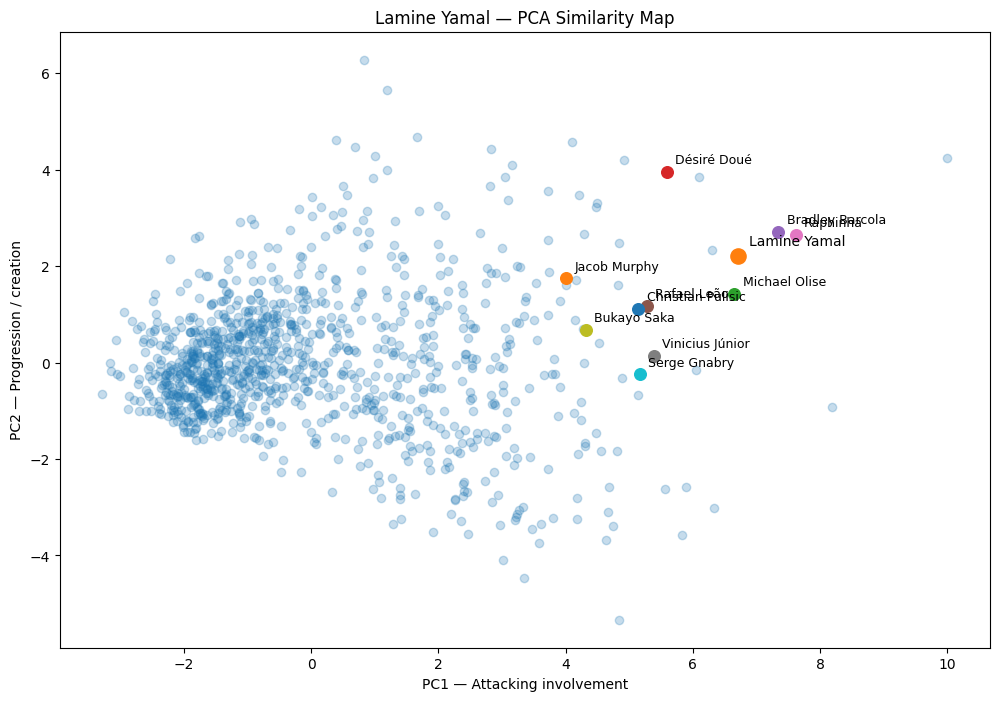

In [16]:
import matplotlib.pyplot as plt

euclidean_top10 = find_similar_players("Lamine Yamal", 10)

plt.figure(figsize=(12, 8))

plt.scatter(
    df["PC1"],
    df["PC2"],
    alpha=0.25
)

lamine = df[df["Player"] == "Lamine Yamal"]

plt.scatter(
    lamine["PC1"],
    lamine["PC2"],
    s=120
)

plt.annotate(
    "Lamine Yamal",
    (lamine["PC1"].iloc[0], lamine["PC2"].iloc[0]),
    xytext=(8, 8),
    textcoords="offset points"
)

for player in euclidean_top10["Player"]:
    player_data = df[df["Player"] == player]

    plt.scatter(
        player_data["PC1"],
        player_data["PC2"],
        s=70
    )

    plt.annotate(
        player,
        (player_data["PC1"].iloc[0], player_data["PC2"].iloc[0]),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("PC1 — Attacking involvement")
plt.ylabel("PC2 — Progression / creation")
plt.title("Lamine Yamal — PCA Similarity Map")

plt.show()

In [17]:
cosine_results = (
    df[df["Player"] != "Lamine Yamal"]
    .sort_values("cosine_similarity", ascending=False)
)

cosine_top10 = cosine_results.head(10)

cosine_top10[[
    "Player",
    "Pos",
    "Squad",
    "cosine_similarity"
]]

,Player,Pos,Squad,cosine_similarity
1116,Ansgar Knauff,"MF,FW",Eintracht Frankfurt,0.975607
1595,Michael Olise,MF,Bayern Munich,0.953768
185,Bradley Barcola,FW,Paris Saint-Germain,0.953597
630,Désiré Doué,"FW,MF",Paris Saint-Germain,0.944007
701,Eberechi Eze,"MF,FW",Arsenal,0.942759
1497,Jacob Murphy,"FW,MF",Newcastle United,0.939937
1869,Bukayo Saka,"FW,MF",Arsenal,0.939649
1190,Rafael Leão,FW,Milan,0.938423
573,Amad Diallo,MF,Manchester Utd,0.937391
1759,Raphinha,"MF,FW",Barcelona,0.933413


In [18]:
euclidean_names = set(euclidean_top10["Player"])
cosine_names = set(cosine_top10["Player"])

overlap = euclidean_names.intersection(cosine_names)

print("Players appearing in both top 10:", len(overlap))
print(overlap)

Players appearing in both top 10: 7
{'Jacob Murphy', 'Michael Olise', 'Bukayo Saka', 'Bradley Barcola', 'Désiré Doué', 'Raphinha', 'Rafael Leão'}


In [19]:
feature_labels = {
    "xG_90": "Expected Goals / 90",
    "xAG_90": "Expected Assists / 90",
    "PrgP_p90": "Progressive Passes / 90",
    "PrgC_p90": "Progressive Carries / 90",
    "PrgR_p90": "Progressive Passes Received / 90",
    "TklW_p90": "Tackles Won / 90",
    "Int_p90": "Interceptions / 90",
    "Sh_p90": "Shots / 90",
    "SoT_p90": "Shots on Target / 90"
}

In [20]:
lamine_idx = df.index[df["Player"] == "Lamine Yamal"][0]
olise_idx = df.index[df["Player"] == "Michael Olise"][0]

lamine_scaled = X_scaled[df.index.get_loc(lamine_idx)]
olise_scaled = X_scaled[df.index.get_loc(olise_idx)]

In [21]:
player_name = "Lamine Yamal"

euclidean_results = find_similar_players(player_name, 10)

cosine_results = (
    df[df["Player"] != player_name]
    .sort_values("cosine_similarity", ascending=False)
    .head(10)
)

comparison = pd.DataFrame({
    "Euclidean": euclidean_results["Player"].tolist(),
    "Cosine": cosine_results["Player"].tolist()
})

comparison

,Euclidean,Cosine
0,Michael Olise,Ansgar Knauff
1,Désiré Doué,Michael Olise
2,Bradley Barcola,Bradley Barcola
3,Rafael Leão,Désiré Doué
4,Raphinha,Eberechi Eze
5,Vinicius Júnior,Jacob Murphy
6,Bukayo Saka,Bukayo Saka
7,Serge Gnabry,Rafael Leão
8,Christian Pulisic,Amad Diallo
9,Jacob Murphy,Raphinha


In [22]:
euclidean_names = set(euclidean_results["Player"])
cosine_names = set(cosine_results["Player"])

overlap = euclidean_names.intersection(cosine_names)
union = euclidean_names.union(cosine_names)

print("Shared players:", len(overlap))
print("Euclidean top 10:", len(euclidean_names))
print("Cosine top 10:", len(cosine_names))
print("Overlap percentage:", len(overlap) / 10 * 100)
print("Jaccard similarity:", len(overlap) / len(union))
print("\nShared players:")
print(sorted(overlap))

Shared players: 7
Euclidean top 10: 10
Cosine top 10: 10
Overlap percentage: 70.0
Jaccard similarity: 0.5384615384615384

Shared players:
['Bradley Barcola', 'Bukayo Saka', 'Désiré Doué', 'Jacob Murphy', 'Michael Olise', 'Rafael Leão', 'Raphinha']


In [23]:
test_players = [
    "Bukayo Saka",
    "Michael Olise",
    "Vinicius Júnior"
]

for player in test_players:
    print(f"\nSimilar players to {player}:")
    display(find_similar_players(player, 5))


Similar players to Bukayo Saka:


,Player,Pos,Squad,euclidean_distance
25,Karim Adeyemi,"MF,FW",Dortmund,1.189937
1116,Ansgar Knauff,"MF,FW",Eintracht Frankfurt,1.484649
821,Serge Gnabry,MF,Bayern Munich,1.802648
646,Paulo Dybala,"FW,MF",Roma,1.906050
448,Samuel Chukwueze,MF,Fulham,2.065345



Similar players to Michael Olise:


,Player,Pos,Squad,euclidean_distance
2265,Lamine Yamal,"MF,FW",Barcelona,2.250464
185,Bradley Barcola,FW,Paris Saint-Germain,2.962270
861,Antoine Griezmann,FW,Atlético Madrid,3.033750
1869,Bukayo Saka,"FW,MF",Arsenal,3.082817
1190,Rafael Leão,FW,Milan,3.152414



Similar players to Vinicius Júnior:


,Player,Pos,Squad,euclidean_distance
1738,Christian Pulisic,FW,Milan,1.756399
1190,Rafael Leão,FW,Milan,1.954949
821,Serge Gnabry,MF,Bayern Munich,2.171255
646,Paulo Dybala,"FW,MF",Roma,2.176347
1869,Bukayo Saka,"FW,MF",Arsenal,2.226790


In [24]:
def compare_players(player_1, player_2):
    idx_1 = df.index[df["Player"] == player_1][0]
    idx_2 = df.index[df["Player"] == player_2][0]

    pos_1 = df.index.get_loc(idx_1)
    pos_2 = df.index.get_loc(idx_2)

    comparison = pd.DataFrame({
        "Feature": features,
        player_1: X.iloc[pos_1].values,
        player_2: X.iloc[pos_2].values,
        "Standardized Difference": abs(
            X_scaled[pos_1] - X_scaled[pos_2]
        )
    })

    comparison["Absolute Difference"] = abs(
        comparison[player_1] - comparison[player_2]
    )

    comparison["Squared Difference"] = (
        X_scaled[pos_1] - X_scaled[pos_2]
    ) ** 2

    total = comparison["Squared Difference"].sum()

    comparison["Contribution %"] = (
        comparison["Squared Difference"] / total
    ) * 100 if total != 0 else 0

    return comparison.sort_values(
        "Contribution %",
        ascending=False
    ).reset_index(drop=True)

In [25]:
compare_players("Bukayo Saka", "Karim Adeyemi")

,Feature,Bukayo Saka,Karim Adeyemi,Standardized Difference,Absolute Difference,Squared Difference,Contribution %
0,TklW_p90,0.670000,0.310000,0.801844,0.360000,0.642953,45.407910
1,Sh_p90,2.870000,2.380000,0.528247,0.490000,0.279045,19.707272
2,PrgC_p90,4.302789,5.230769,0.509867,0.927980,0.259964,18.359711
3,PrgP_p90,3.137450,2.153846,0.326188,0.983604,0.106399,7.514296
4,SoT_p90,1.170000,1.080000,0.221714,0.090000,0.049157,3.471664
5,xAG_90,0.400000,0.380000,0.213140,0.020000,0.045429,3.208357
6,xG_90,0.360000,0.340000,0.118486,0.020000,0.014039,0.991483
7,Int_p90,0.670000,0.620000,0.109847,0.050000,0.012066,0.852171
8,PrgR_p90,11.429283,11.769231,0.083052,0.339948,0.006898,0.487136


In [26]:
comparison_check = compare_players(
    "Bukayo Saka",
    "Karim Adeyemi"
)

print(
    "Total feature contribution:",
    comparison_check["Contribution %"].sum()
)

print(
    "Euclidean distance:",
    np.sqrt(comparison_check["Squared Difference"].sum())
)

display(comparison_check)

Total feature contribution: 100.0
Euclidean distance: 1.1899370758331207


,Feature,Bukayo Saka,Karim Adeyemi,Standardized Difference,Absolute Difference,Squared Difference,Contribution %
0,TklW_p90,0.670000,0.310000,0.801844,0.360000,0.642953,45.407910
1,Sh_p90,2.870000,2.380000,0.528247,0.490000,0.279045,19.707272
2,PrgC_p90,4.302789,5.230769,0.509867,0.927980,0.259964,18.359711
3,PrgP_p90,3.137450,2.153846,0.326188,0.983604,0.106399,7.514296
4,SoT_p90,1.170000,1.080000,0.221714,0.090000,0.049157,3.471664
5,xAG_90,0.400000,0.380000,0.213140,0.020000,0.045429,3.208357
6,xG_90,0.360000,0.340000,0.118486,0.020000,0.014039,0.991483
7,Int_p90,0.670000,0.620000,0.109847,0.050000,0.012066,0.852171
8,PrgR_p90,11.429283,11.769231,0.083052,0.339948,0.006898,0.487136
